# 32회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 주택가치 설명의 진단

이 회차는 통계 복기에서 확인한 유형만 재구성한 부분 묶음이다. housing.csv의 행은 독립 지역 표본이며 target과 x1~x5를 포함한다. 같은 관측 순서로 분석한다. 표본 순서는 임의 순서이며 실제 시계열이 아니다.

### 1-1

**문제** 다중 선형모형의 전체 가설·계수와 잔차 그림을 제시하고, 정규성·등분산성·함수형태 진단을 각각 구분해 수행하시오. 전체 F의 유의성과 선형성 진단의 차이를 설명하시오.

**풀이·선택 근거·해석**

전체 F 유의성만으로 선형성이 확인되지 않는다. 함수형태는 RESET/잔차 그림, 분산은 BP, 정규성은 JB 등 별도 진단으로 평가한다. 임의 행 순서의 DW를 시간 독립성 증명에 쓰지 않는다.


=== 1-1 ===
coefficients
[
  {
    "index": "const",
    "coef": 21.111973856244035,
    "SE": 0.16047082038981256,
    "t": 131.56269660091002,
    "p": 2.2835291198355487e-221
  },
  {
    "index": "x1",
    "coef": 2.6559901785823015,
    "SE": 0.9716374519281114,
    "t": 2.7335197643027973,
    "p": 0.006744991482082016
  },
  {
    "index": "x2",
    "coef": 0.3731139892505402,
    "SE": 1.0127049957379903,
    "t": 0.3684330489340977,
    "p": 0.7128834523176675
  },
  {
    "index": "x3",
    "coef": -2.1420757784697955,
    "SE": 0.14646996381757282,
    "t": -14.624676094941444,
    "p": 7.719371754721668e-35
  },
  {
    "index": "x4",
    "coef": 0.5357612931121218,
    "SE": 0.15510080352482408,
    "t": 3.454277998156035,
    "p": 0.0006549088095179889
  },
  {
    "index": "x5",
    "coef": -0.27127043938706263,
    "SE": 0.16386499573129737,
    "t": -1.655450806784181,
    "p": 0.09917355787449982
  }
]
fit
{
  "R2": 0.7188109227619526,
  "n": 240.0
}
{
  "method": "O

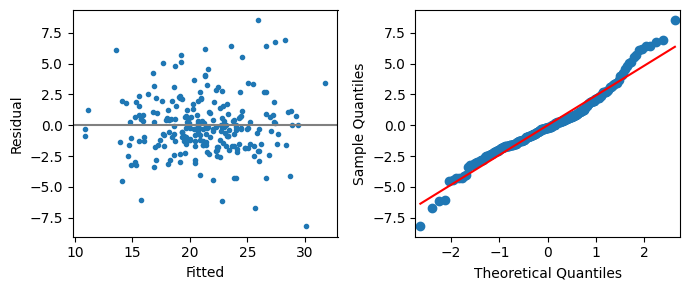

In [2]:
ctx.run('1-1', 'housing_diagnostics')

### 1-2

**문제** 특성 공선성을 확인하고 표준화 후 모든 주성분으로 회귀한 모형과 원래 회귀의 적합값을 비교하시오. 왜 모든 주성분 유지가 기존 잔차 문제를 자동 해결하지 않는지 설명하시오.

**풀이·선택 근거·해석**

가역적인 모든 주성분 변환은 같은 설명변수 공간이다. 절편 포함 OLS의 적합값은 같아진다. PCA가 잔차 자기상관·이분산을 자동 교정한다는 해설은 배제한다.

In [3]:
ctx.run('1-2', 'housing_pca')


=== 1-2 ===
all-component invariance
{
  "max_abs_fitted_difference": 3.197442310920451e-14,
  "variance_ratio": [
    0.3983998645819496,
    0.2126641724956773,
    0.19593290714014014,
    0.190514785110857,
    0.0024882706713760085
  ]
}


### 1-3

**문제** 원모형의 HC3 강건 표준오차와 통상 표준오차를 비교하시오. 모형 가정 위반에 대한 대안을 제시하고 강건 표준오차가 해결하는 것과 해결하지 못하는 것을 구분하시오.

**풀이·선택 근거·해석**

HC3는 독립 관측 하 이분산성에 견고한 추론용 보정이다. 평균 함수 오지정·시간 의존성·내생성을 자동으로 해결하지 않는다.

In [4]:
ctx.run('1-3', 'housing_robust')


=== 1-3 ===
SE comparison
[
  {
    "index": "const",
    "OLS_SE": 0.16047082038981256,
    "HC3_SE": 0.16274869255085248,
    "HC3_p": 5.911934117414378e-220
  },
  {
    "index": "x1",
    "OLS_SE": 0.9716374519281114,
    "HC3_SE": 0.985481210145644,
    "HC3_p": 0.0075467879821828785
  },
  {
    "index": "x2",
    "OLS_SE": 1.0127049957379903,
    "HC3_SE": 0.9650236162617495,
    "HC3_p": 0.6993762012173304
  },
  {
    "index": "x3",
    "OLS_SE": 0.14646996381757282,
    "HC3_SE": 0.14341498936849942,
    "HC3_p": 7.059058441406739e-36
  },
  {
    "index": "x4",
    "OLS_SE": 0.15510080352482408,
    "HC3_SE": 0.2414633958832584,
    "HC3_p": 0.02745988298223895
  },
  {
    "index": "x5",
    "OLS_SE": 0.16386499573129737,
    "HC3_SE": 0.18103270757336032,
    "HC3_p": 0.13536133298336409
  }
]


## 2. 희소 범주표와 두 집단 비교

category.csv는 독립 자동차 관측의 cyl·gear다. salary.csv는 서로 독립인 두 집단의 급여다. 범주표의 전체 독립성과 급여 분포의 차이가 관심사다. 급여 차이를 평균 차이로 한정하지 않는다.

### 2-1

**문제** cyl×gear 관측/기대도수를 만들고 근사 검정의 적합성을 평가하시오. 희소 셀이 있을 때 원표의 전체 관계를 검정하는 대안을 설명하시오.

**풀이·선택 근거·해석**

기대도수를 확인한다. 여러 2×2 부분표에서 최소 p만 선택해 전체 독립성을 판단하는 풀이를 사용하지 않는다.

In [5]:
ctx.run('2-1', 'category_expected')


=== 2-1 ===
table
[
  {
    "cyl": 4,
    "3": 9,
    "4": 1,
    "5": 0
  },
  {
    "cyl": 6,
    "3": 2,
    "4": 7,
    "5": 1
  },
  {
    "cyl": 8,
    "3": 0,
    "4": 1,
    "5": 4
  }
]
expected
[
  [
    4.4,
    3.6,
    2.0
  ],
  [
    4.4,
    3.6,
    2.0
  ],
  [
    2.2,
    1.8,
    1.0
  ]
]
small expected cells
9


### 2-2

**문제** 행·열 주변합을 조건으로 한 무작위 표 4999개(seed=32)를 생성해 전체 독립성을 평가하시오. 관측 Pearson 통계량, (초과횟수+1)/(4999+1) 형태 p-value·Monte Carlo 표준오차·기각 여부를 제시하시오.

**풀이·선택 근거·해석**

전체 RxC 표에 대해 고정 주변합 Monte Carlo 조건부 검정을 수행한다. 이산 정확 검정의 근사 p이며 시뮬레이션 오차가 있다.

In [6]:
ctx.run('2-2', 'category_mc')


=== 2-2 ===
Monte Carlo detail
{
  "observed": [
    [
      9,
      1,
      0
    ],
    [
      2,
      7,
      1
    ],
    [
      0,
      1,
      4
    ]
  ],
  "expected": [
    [
      4.4,
      3.6,
      2.0
    ],
    [
      4.4,
      3.6,
      2.0
    ],
    [
      2.2,
      1.8,
      1.0
    ]
  ],
  "simulations": 4999,
  "exceed": 1,
  "MC_SE": 0.00028278613827413816,
  "row_sums": [
    10,
    10,
    5
  ],
  "col_sums": [
    11,
    9,
    5
  ]
}
{
  "method": "Fixed-margin RxC Pearson Monte Carlo",
  "H0": "cyl independent of gear",
  "H1": "not independent",
  "statistic": 25.262626262626263,
  "p_value": 0.0004,
  "df": null,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 자동차 범주 간 전체 관련성에 대한 근거가 있다."
}


### 2-3

**문제** 두 집단 급여의 분포·이상치를 확인하고 순위를 이용해 분포의 차이를 평가하시오. 검정 선택·가정·H0/H1·통계량·p-value·기각 여부를 제시하고 자동으로 중앙값 차이라고 해석할 수 있는지 설명하시오.

**풀이·선택 근거·해석**

Mann-Whitney의 독립 표본 분포 동일성 H0를 사용한다. 분포 형태가 다르면 위치/중앙값만의 차이로 해석하지 않는다. 정규성 p 하나로 검정을 기계적으로 선택하지 않는다.

In [7]:
ctx.run('2-3', 'salary')


=== 2-3 ===
group summaries
[
  {
    "group": "A",
    "count": 120.0,
    "mean": 151.20823752583334,
    "std": 54.34235751862228,
    "min": 61.5814833,
    "25%": 112.3098335,
    "50%": 140.649454,
    "75%": 176.1007415,
    "max": 380.078749
  },
  {
    "group": "B",
    "count": 120.0,
    "mean": 207.0959910908333,
    "std": 138.05685972507467,
    "min": 32.6128352,
    "25%": 117.6582275,
    "50%": 171.763878,
    "75%": 253.18632725,
    "max": 965.130548
  }
]
{
  "method": "Mann-Whitney U",
  "H0": "same distributions",
  "H1": "different distributions",
  "statistic": 5621.0,
  "p_value": 0.00333276545094874,
  "df": null,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 두 급여 분포의 차이에 대한 근거가 있다."
}
